In [1]:
import pandas as pd
from bauer.models import RiskRegressionModel
import seaborn as sns

WARNING (aesara.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


In [2]:
df = pd.read_csv('/data/ds-stressrisk/sourcedata/all_behavior_df.csv', index_col=[0, 1,2,3,])

In [26]:
model = RiskRegressionModel(df.reset_index('session'), regressors={'n1_evidence_sd':'session*group',
    'n2_evidence_sd':'session*group', 'prior_mu':'0+session*group', 'risky_prior_std':'session*group', 'safe_prior_std':'session*group'},
    prior_estimate='full')

In [28]:
model.build_estimation_model()
idata = model.sample(draws=100, tune=100)

Only 100 samples in chain.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [n1_evidence_sd_mu, n1_evidence_sd_sd, n1_evidence_sd_offset, n2_evidence_sd_mu, n2_evidence_sd_sd, n2_evidence_sd_offset, risky_prior_mu_mu, risky_prior_mu_sd, risky_prior_mu_offset, risky_prior_std_mu, risky_prior_std_sd, risky_prior_std_offset, safe_prior_mu_mu, safe_prior_mu_sd, safe_prior_mu_offset, safe_prior_std_mu, safe_prior_std_sd, safe_prior_std_offset, prior_mu_mu, prior_mu_sd, prior_mu_offset]
WARNING (aesara.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (aesara.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (aesara.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (aesara.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 100 tune and 100 draw iterations (400 + 400 draws total) took 643 seconds.
The acceptance probability does not match the target. It is 0.8969, but should be close to 0.8. Try to increase the number of tuning steps.


In [34]:
idata.posterior['risky_prior_mu_mu'].to_dataframe()

risky_prior_mu_mu
chain draw risky_prior_mu_regressors                   
0     0    Intercept                           3.130586
      1    Intercept                           3.114617
      2    Intercept                           3.190078
      3    Intercept                           3.567998
      4    Intercept                           3.219169
...                                                 ...
3     95   Intercept                           3.091626
      96   Intercept                           3.158363
      97   Intercept                           3.406976
      98   Intercept                           2.964304
      99   Intercept                           3.024981

[400 rows x 1 columns]

In [35]:
idata.posterior['safe_prior_mu_mu'].to_dataframe()

safe_prior_mu_mu
chain draw safe_prior_mu_regressors                  
0     0    Intercept                         3.065552
      1    Intercept                         2.931662
      2    Intercept                         2.907903
      3    Intercept                         3.256961
      4    Intercept                         3.019049
...                                               ...
3     95   Intercept                         3.094537
      96   Intercept                         3.267424
      97   Intercept                         3.278694
      98   Intercept                         3.109054
      99   Intercept                         2.950671

[400 rows x 1 columns]

In [36]:
 idata.posterior['prior_mu_mu'].to_dataframe()

prior_mu_mu
chain draw prior_mu_regressors             
0     0    session                -0.106979
           group                   0.222082
           session:group           0.481226
      1    session                -0.059444
           group                   0.205533
...                                     ...
3     98   group                  -0.197247
           session:group           0.319401
      99   session                 0.084867
           group                  -0.219456
           session:group           0.299804

[1200 rows x 1 columns]

/var/folders/d4/cpqhwlbn301clph1qk64k01nmjkty3/T/ipykernel_74320/2901898887.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(tmp.xs('session', 0, -1))


<Axes: ylabel='Density'>

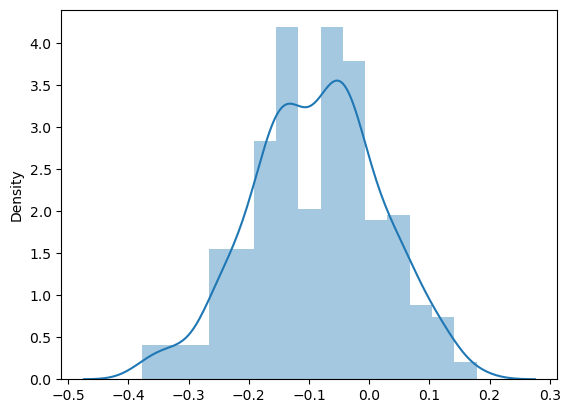

In [31]:
sns.distplot(tmp.xs('session', 0, -1))

/var/folders/d4/cpqhwlbn301clph1qk64k01nmjkty3/T/ipykernel_74320/2293620666.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(tmp.xs('group', 0, -1))


<Axes: ylabel='Density'>

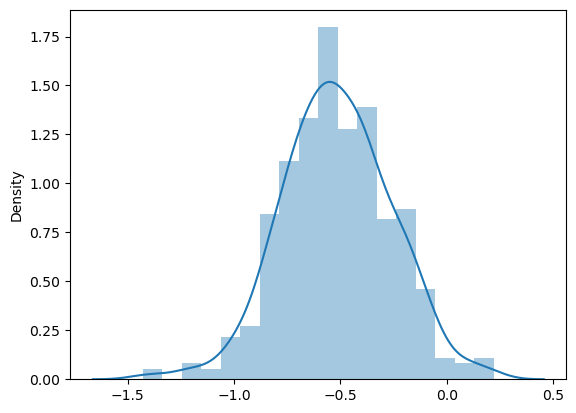

In [32]:
sns.distplot(tmp.xs('group', 0, -1))

/var/folders/d4/cpqhwlbn301clph1qk64k01nmjkty3/T/ipykernel_74320/1620729489.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(tmp.xs('session:group', 0, -1))


<Axes: ylabel='Density'>

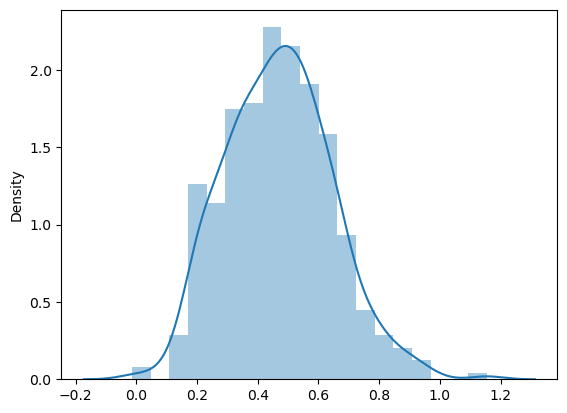

In [33]:
sns.distplot(tmp.xs('session:group', 0, -1))

In [ ]:
model2 = RiskRegressionModel(df.reset_index('session'), regressors={'n1_evidence_sd':'session*group',
    'n2_evidence_sd':'session*group', 'prior_mu':'0+session*group', 'risky_prior_std':'session*group', 'safe_prior_std':'session*group'},
    prior_estimate='full')